# Kenya extra inputs: construction and model-fit audit

This executed notebook reproduces the Zimbabwe/Malawi audit for the Kenya OAF 2019–2020 point cohort. It validates the six Earth Engine exports, constructs model-ready tables, and checks field-scale usefulness inside 2 km clusters.

In [1]:
from pathlib import Path
import json, os
import pandas as pd
import matplotlib.pyplot as plt
ROOT = Path(os.environ.get('KENYA_MALAWI_EXTRA_INPUTS_ROOT', '../Google Earth/Kenya Malawi')).resolve()
DERIVED, REPORTS = ROOT/'derived', ROOT/'reports'
monthly = pd.read_parquet(DERIVED/'kenya_model_ready_monthly_extra_inputs.parquet')
static = pd.read_parquet(DERIVED/'kenya_model_ready_static_extra_inputs.parquet')
print(f'Monthly: {monthly.shape}; static: {static.shape}')

Monthly: (31816, 28); static: (3977, 108)


## 1. Canonical structure

Each of 3,977 observations contributes eight February–September rows. The feature tables exclude the yield target and are joined to labels later by `obs_id`.

In [2]:
cohort_summary = static.groupby('season_year', as_index=False).agg(fields=('obs_id','size'), median_elevation_m=('elevation','median'), median_slope_deg=('slope','median'), soilgrids_complete=('soilgrids_complete','sum'))
cohort_summary

 season_year  fields  median_elevation_m  median_slope_deg  soilgrids_complete
        2019    1768              1492.0          3.818481                1723
        2020    2209              1516.0          3.818605                2181


## 2. Source completeness

    source  complete  expected time_scale    percent
Sentinel-1     31816     31816    monthly 100.000000
 ERA5-Land     31816     31816    monthly 100.000000
    CHIRPS     31816     31816    monthly 100.000000
      SRTM      3977      3977     static 100.000000
 SoilGrids      3904      3977     static  98.164446
AlphaEarth      3977      3977     annual 100.000000


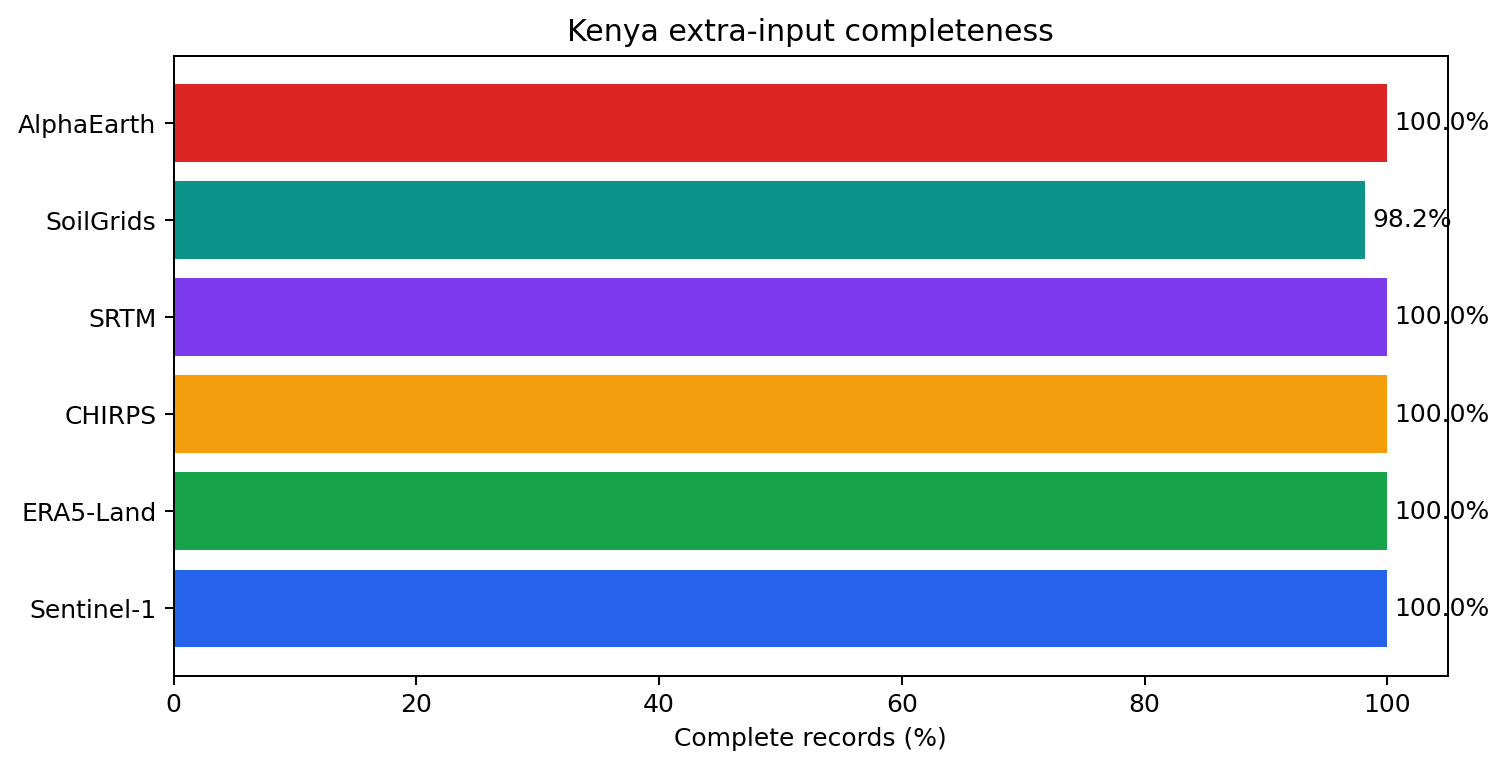

In [3]:
completeness = pd.DataFrame([['Sentinel-1',monthly.s1_available.sum(),len(monthly)],['ERA5-Land',monthly.era5_available.sum(),len(monthly)],['CHIRPS',monthly.chirps_available.sum(),len(monthly)],['SRTM',static[['elevation','slope']].notna().all(axis=1).sum(),len(static)],['SoilGrids',static.soilgrids_complete.sum(),len(static)],['AlphaEarth',static.alphaearth_complete.sum(),len(static)]],columns=['source','complete','expected']); completeness['percent']=100*completeness.complete/completeness.expected; completeness

## 3. Sentinel-1 coverage and point support

Both orbit directions are available for all months. The registered rule selects descending on ties. The model uses the 3×3 median: it is more robust than one pixel, but it is not an exact field mean because Kenya has GPS points rather than field polygons.

Point vs 3x3 MAE: {'VV': 0.3112053718827158, 'VH': 0.33552980636699925}
Complete seasons: 3977


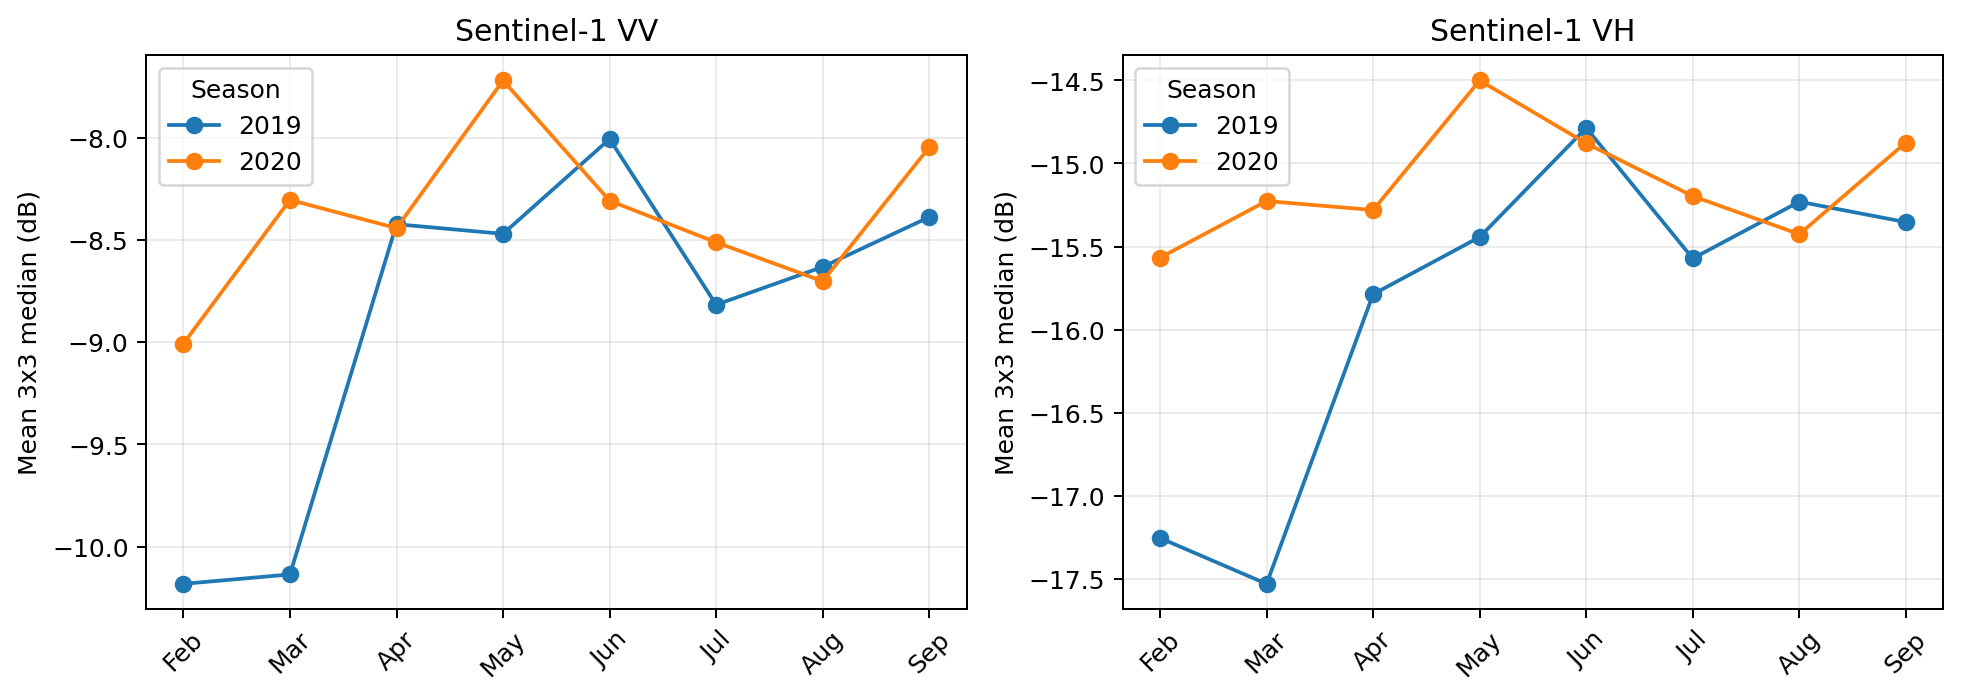

In [4]:
quality=json.loads((REPORTS/'kenya_feature_quality_summary.json').read_text()); print('Point vs 3x3 MAE:', quality['sentinel1_point_vs_3x3_mae_db']); print('Complete seasons:', quality['sentinel1_complete_seasons'])

## 4. Weather consistency

ERA5-Land and CHIRPS are complete but agree less strongly than in Malawi. They are coarse contextual predictors, not field-resolving measurements.

CHIRPS–ERA5 rainfall correlation: 0.529


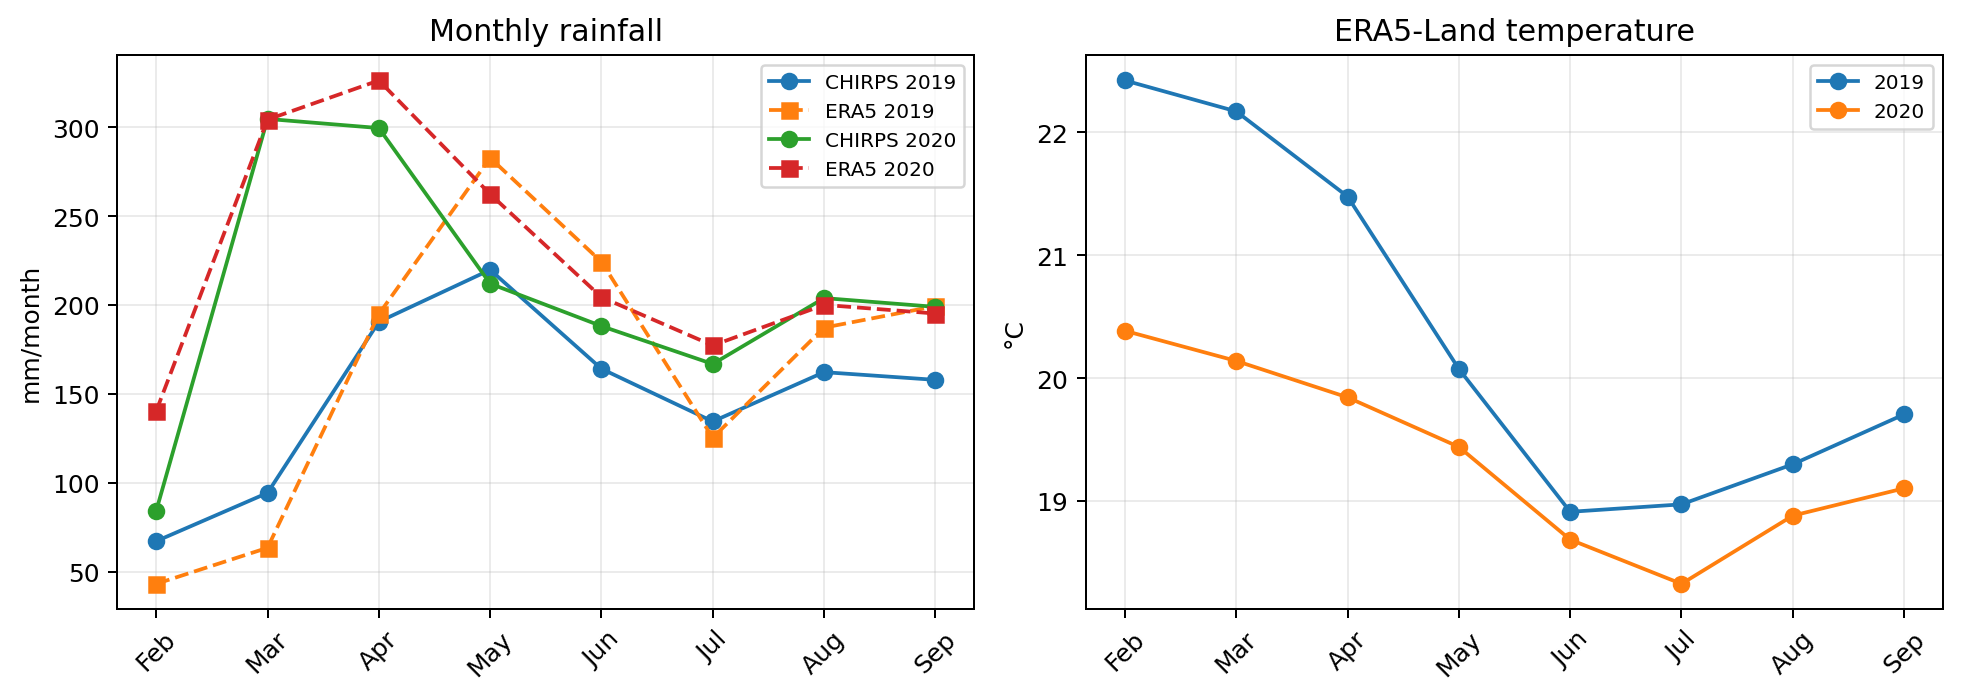

In [5]:
print('CHIRPS–ERA5 rainfall correlation:', round(quality['chirps_era5_precipitation_correlation'],3))

## 5. Can sources distinguish fields inside a village?

The calculation uses 568 two-kilometre clusters with multiple observations. Sentinel-1, SRTM and AlphaEarth vary in most clusters. Weather varies less often, consistent with its coarse resolution.

                     source       resolution  multi_field_2km_clusters  clusters_with_more_than_one_value  share_varying_within_2km
Sentinel-1 VV seasonal mean  10 m 3x3 median                       568                                556                  0.978873
   CHIRPS seasonal rainfall          ~5.5 km                       568                                275                  0.484155
ERA5-Land seasonal rainfall           ~11 km                       568                                228                  0.401408
             SRTM elevation             30 m                       568                                536                  0.943662
        SoilGrids pH 0-5 cm            250 m                       568                                371                  0.653169
       SoilGrids SOC 0-5 cm            250 m                       568                                493                  0.867958
             AlphaEarth A00 10 m point pixel                       568      

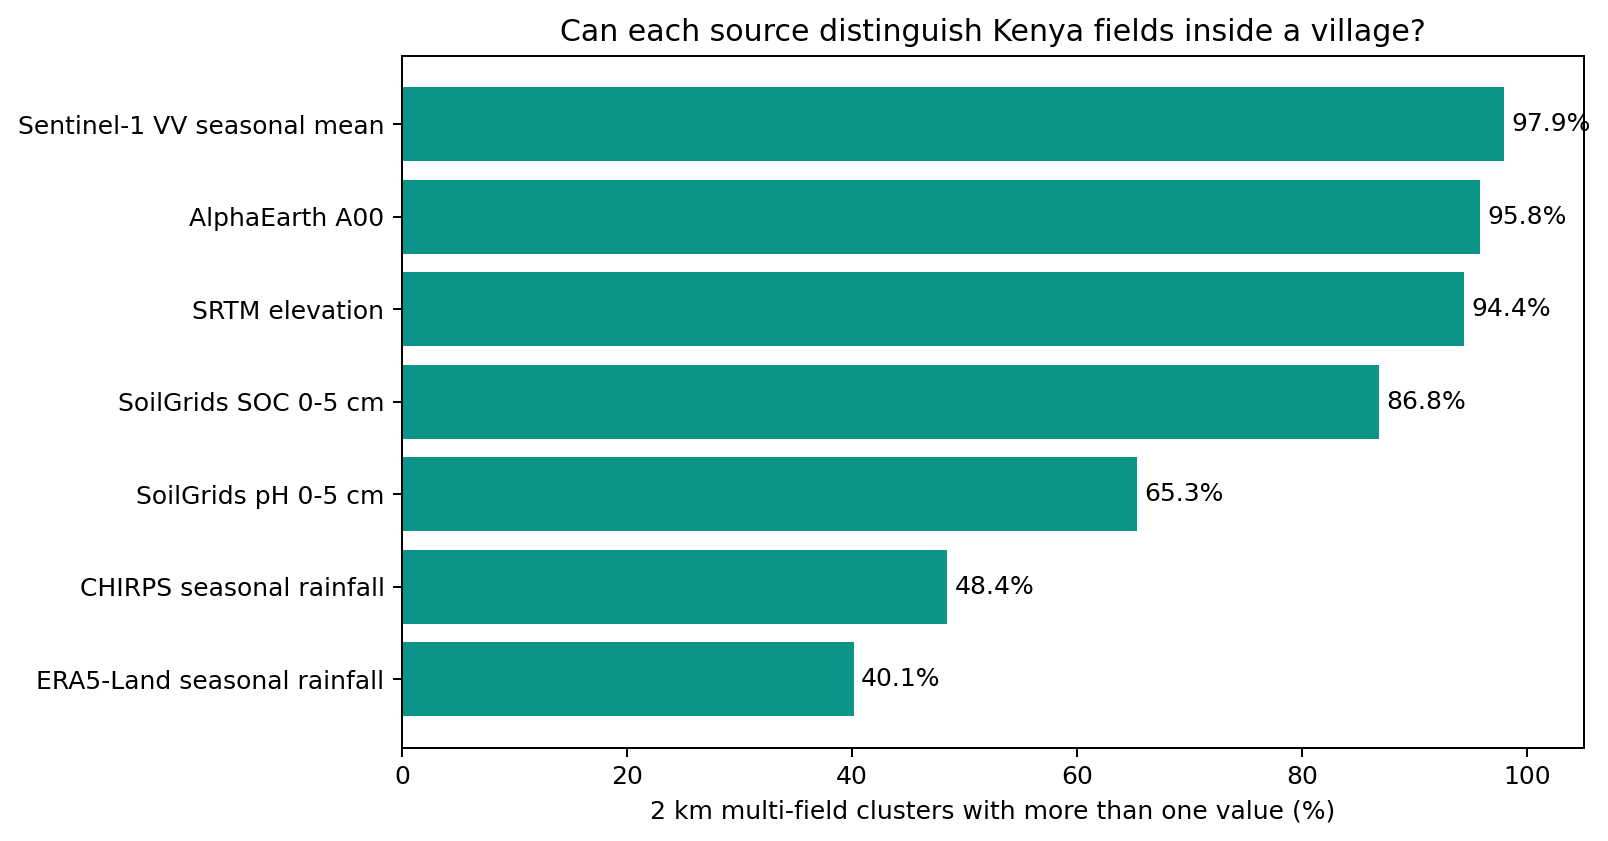

In [6]:
variation=pd.read_csv(REPORTS/'kenya_within_village_variation.csv'); variation

## 6. AlphaEarth, SoilGrids and modelling decisions

AlphaEarth is complete in all 64 dimensions and its median vector norm is 1.0001. However, calendar-year embeddings include October–December after the February–September crop window, so they remain a separate representation baseline.

SoilGrids is complete for 3,904 fields. The 73 all-layer no-data cases are retained with `soilgrids_complete = false`; they must be imputed within training folds or handled with a mask, never silently converted to physical zeros.

The Presto-compatible monthly table contains Sentinel-1 VV/VH, ERA5 temperature/rainfall, and SRTM elevation/slope. CHIRPS and SoilGrids are optional additions.

In [7]:
status=pd.DataFrame([['Canonical keys','complete','31,816 unique field-month rows'],['Sentinel-1','complete','31,816/31,816'],['ERA5-Land','complete','31,816/31,816'],['CHIRPS','complete','31,816/31,816'],['SRTM','complete','3,977/3,977'],['SoilGrids','partial','3,904/3,977'],['AlphaEarth','complete with leakage warning','3,977/3,977; 64 dimensions'],['Presto use','ready','Required added channels complete']],columns=['item','status','evidence']); status

          item                        status                               evidence
Canonical keys                      complete         31,816 unique field-month rows
    Sentinel-1                      complete    31,816/31,816; descending tie-break
     ERA5-Land                      complete                          31,816/31,816
        CHIRPS                      complete                          31,816/31,816
          SRTM                      complete                            3,977/3,977
     SoilGrids                       partial 3,904/3,977; 73 genuine no-data points
    AlphaEarth complete with leakage warning             3,977/3,977; 64 dimensions
    Presto use                         ready   Required added channels are complete


## Final conclusion

The Kenya extra-input extension is ready for modelling. All required added Presto channels are complete. Sentinel-1, terrain and AlphaEarth can vary at the scale needed for within-village comparisons, but the absence of field boundaries remains a fundamental interpretation limit. The next scientific step is a controlled comparison on the frozen spatial and temporal splits.